# Franck–Hertz experiment with mercury: the first excitation energy

Electrons accelerated through mercury vapour lose energy in discrete steps when they
excite Hg atoms, so the anode current shows a series of maxima and minima as the
accelerating voltage $U_2$ increases. The spacing between successive extrema is close
to the excitation energy, but it grows with order because electrons gain extra
energy over their mean free path before colliding. This notebook:

1. chooses the tube's operating point from calibration scans (contrast and signal-to-noise),
2. extracts the extremum positions from 15 sweeps at that operating point,
3. fits the spacings with the model of Rapior et al. (2006) to obtain the excitation energy $E_a$,
4. checks correlations, systematic effects of the smoothing, and one outlying run.

All helper functions are in [`fh_analysis.py`](fh_analysis.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import fh_analysis as fh

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

YLABEL = r"$I_a$ (nA)"
cal = fh.DATA / "calibration"

## 1. From raw sweep to extremum positions

Each sweep is first **despiked** (points far from a running median are replaced by
interpolation), then **smoothed** with a Savitzky–Golay filter. Maxima and minima are
found with a prominence threshold and a minimum separation, and extrema too close to
the end of the sweep are discarded. $U_2$ is itself noisy, so it is smoothed along the
sample index as well.

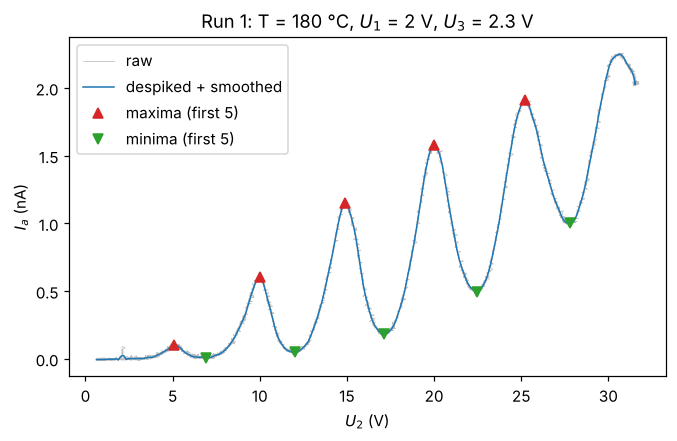

In [2]:
example = fh.load_fh(fh.DATA / "final" / "run01.dat")
mx, mn, sm = fh.find_extrema(example)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(*example, color="0.75", lw=0.5, label="raw")
ax.plot(*sm, color="C0", lw=1, label="despiked + smoothed")
ax.plot(*mx[:, :5], "^", color="C3", label="maxima (first 5)")
ax.plot(*mn[:, :5], "v", color="C2", label="minima (first 5)")
ax.set(xlabel="$U_2$ (V)", ylabel=YLABEL, title="Run 1: T = 180 °C, $U_1$ = 2 V, $U_3$ = 2.3 V")
ax.legend()
fig.savefig(FIG / "example_sweep.png")
plt.show()

## 2. Choosing the operating point

The shape of the curve depends on the oven temperature $T$ (vapour density), the
control-grid voltage $U_1$ and the braking voltage $U_3$. Two figures of merit are used
for each maximum:

* contrast $C = (I_\max - I_\min)/(I_\max + I_\min)$, pairing each maximum with the following minimum,
* $\mathrm{SNR} = I_\max^2 / I_\mathrm{noise}^2$, with $I_\mathrm{noise}$ the standard deviation of the signal before the current starts to rise.

The first order is not visible in every setting, so the settings are compared on the
orders present in all of them. The signal maximum is also listed, to check that nothing
clips at the 5 V limit of the interface.

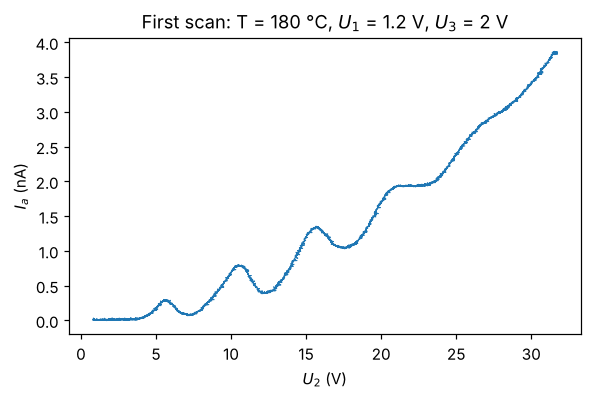

In [3]:
first = fh.load_fh(cal / "scan1_T180_U1-1.2_U3-2.0.dat")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(*first, lw=0.6)
ax.set(xlabel="$U_2$ (V)", ylabel=YLABEL, title="First scan: T = 180 °C, $U_1$ = 1.2 V, $U_3$ = 2 V")
plt.show()

### Scan A: temperature and braking voltage ($U_1$ = 1.2 V)

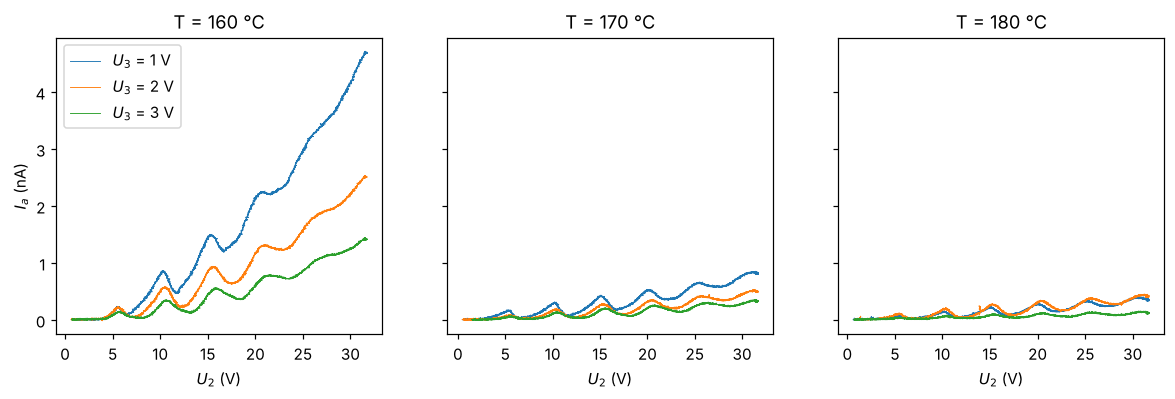

Contrast per order:


order       1     2     3     4     5
T   U3                               
160 1.0  0.41  0.29  0.10   NaN   NaN
    2.0   NaN  0.42  0.18  0.03   NaN
    3.0  0.55  0.44  0.20  0.04   NaN
170 1.0  0.63  0.59  0.39  0.18  0.05
    2.0  0.55  0.61  0.46  0.26  0.09
    3.0  0.50  0.57  0.46  0.27  0.11
180 1.0  0.49  0.52  0.46  0.29  0.15
    2.0  0.63  0.64  0.52  0.33  0.16
    3.0   NaN  0.38  0.39  0.32  0.22

mean C (orders 2–3)  min SNR (orders 2–3)  max signal (V)
T   U3                                                            
160 1.0                0.196             21836.325           4.718
    2.0                0.303              8094.063           2.527
    3.0                0.323              2449.885           1.445
170 1.0                0.491              1112.947           0.855
    2.0                0.535               795.459           0.533
    3.0                0.515               692.586           0.377
180 1.0                0.491               279.967           1.395
    2.0                0.579               453.556           1.058
    3.0                0.382                97.451           0.160

Highest contrast: T = 180 °C, U3 = 2 V


In [4]:
T_list, U3_list = [160, 170, 180], [1.0, 2.0, 3.0]
scanA = {(T, U3): fh.load_fh(cal / f"scan2_T{T}_U1-1.2_U3-{U3:.1f}.dat")
         for T in T_list for U3 in U3_list}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, T in zip(axes, T_list):
    for U3 in U3_list:
        ax.plot(*fh.despike(scanA[T, U3]), lw=0.6, label=f"$U_3$ = {U3:g} V")
    ax.set(xlabel="$U_2$ (V)", title=f"T = {T} °C")
axes[0].set_ylabel(YLABEL); axes[0].legend()
fig.savefig(FIG / "scan_temperature.png")
plt.show()

C_A, SNR_A, sum_A = fh.compare_settings(scanA, ["T", "U3"])
print("Contrast per order:"); display(C_A.round(2))
display(sum_A.round(3))
best_A = sum_A.iloc[:, 0].idxmax()
print(f"Highest contrast: T = {best_A[0]} °C, U3 = {best_A[1]:g} V")

### Scan B: control-grid and braking voltage (T = 180 °C)

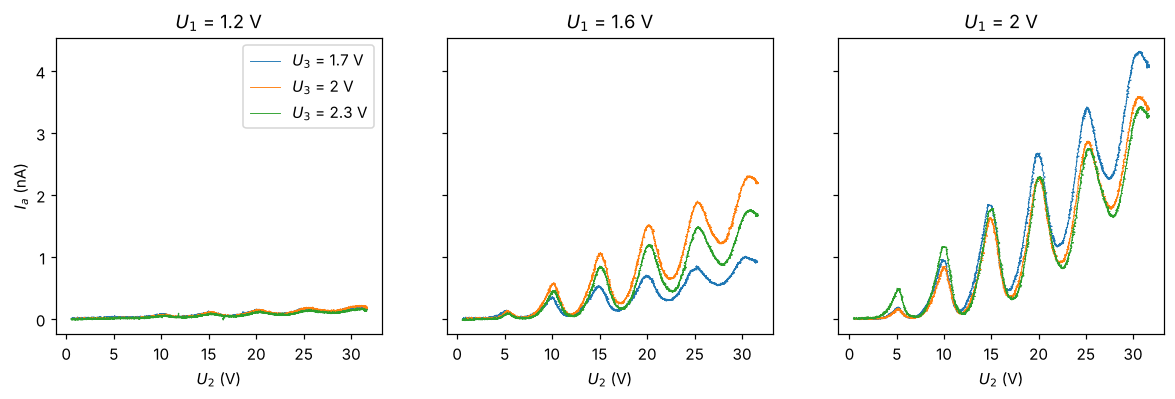

Contrast per order:


order       1     2     3     4     5
U1  U3                               
1.2 1.7   NaN  0.38  0.36  0.26  0.15
    2.0   NaN  0.37  0.37  0.28  0.15
    2.3   NaN  0.41  0.47  0.25  0.15
1.6 1.7  0.66  0.73  0.59  0.39  0.21
    2.0   NaN  0.78  0.61  0.40  0.21
    2.3   NaN  0.82  0.67  0.46  0.26
2.0 1.7  0.79  0.78  0.60  0.39  0.20
    2.0  0.76  0.80  0.64  0.43  0.23
    2.3  0.86  0.87  0.69  0.47  0.25

mean C (orders 2–5)  min SNR (orders 2–5)  max signal (V)
U1  U3                                                            
1.2 1.7                0.290               127.569           0.213
    2.0                0.293               182.732           0.222
    2.3                0.320                67.101           0.172
1.6 1.7                0.478              2497.643           1.015
    2.0                0.502              7636.013           2.312
    2.3                0.549              4458.197           1.765
2.0 1.7                0.492             32484.488           4.320
    2.0                0.525             19597.175           3.590
    2.3                0.570             15842.093           3.430

Highest contrast: U1 = 2 V, U3 = 2.3 V


In [5]:
U1_list, U3B_list = [1.2, 1.6, 2.0], [1.7, 2.0, 2.3]
scanB = {(U1, U3): fh.load_fh(cal / f"scan3_T180_U1-{U1:.1f}_U3-{U3:.1f}.dat")
         for U1 in U1_list for U3 in U3B_list}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, U1 in zip(axes, U1_list):
    for U3 in U3B_list:
        ax.plot(*fh.despike(scanB[U1, U3]), lw=0.6, label=f"$U_3$ = {U3:g} V")
    ax.set(xlabel="$U_2$ (V)", title=f"$U_1$ = {U1:g} V")
axes[0].set_ylabel(YLABEL); axes[0].legend()
fig.savefig(FIG / "scan_grid_voltages.png")
plt.show()

C_B, SNR_B, sum_B = fh.compare_settings(scanB, ["U1", "U3"])
print("Contrast per order:"); display(C_B.round(2))
display(sum_B.round(3))
best_B = sum_B.iloc[:, 0].idxmax()
print(f"Highest contrast: U1 = {best_B[0]:g} V, U3 = {best_B[1]:g} V")

## 3. The final measurement: 15 sweeps

All 15 sweeps were taken at T = 180 °C, $U_1$ = 2 V, $U_3$ = 2.3 V. Overlaying them and
following the current at each extremum run by run shows whether the tube drifted
(e.g. as the oven temperature settled).

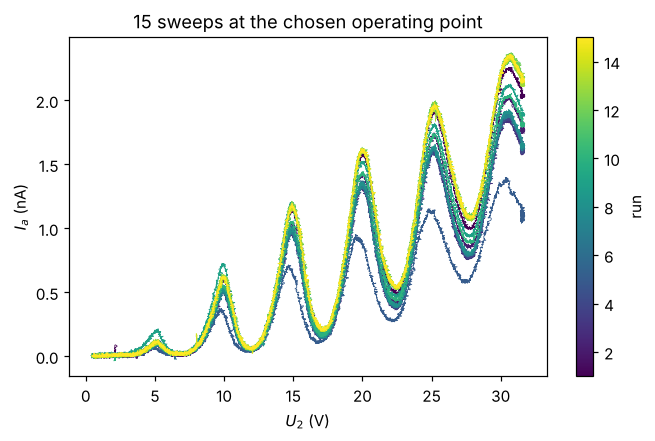

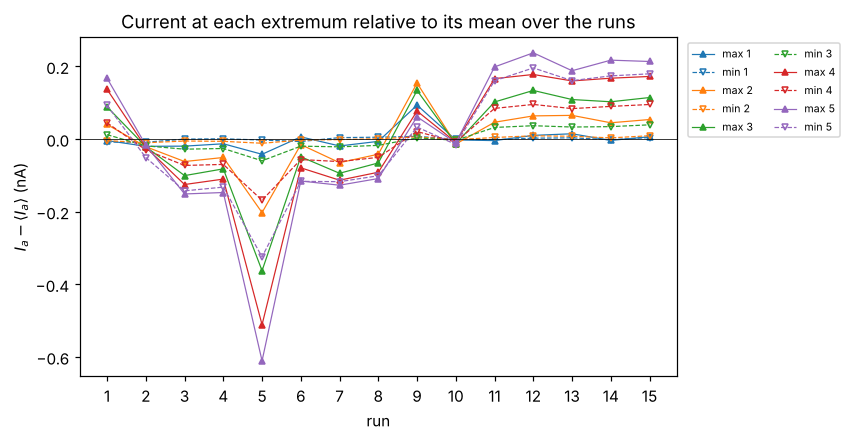

In [6]:
runs = [fh.load_fh(p) for p in sorted((fh.DATA / "final").glob("run*.dat"))]
N = len(runs)
cmap = plt.cm.viridis

fig, ax = plt.subplots(figsize=(7, 4))
for d, col in zip(runs, cmap(np.linspace(0, 1, N))):
    ax.plot(*fh.despike(d), color=col, lw=0.5)
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(1, N)), ax=ax, label="run")
ax.set(xlabel="$U_2$ (V)", ylabel=YLABEL, title=f"{N} sweeps at the chosen operating point")
fig.savefig(FIG / "final_runs_overlay.png")
plt.show()

ext = [fh.find_extrema(d) for d in runs]
I_max = np.array([e[0][1, :5] for e in ext])
I_min = np.array([e[1][1, :5] for e in ext])
run_no = np.arange(1, N + 1)

fig, ax = plt.subplots(figsize=(7, 4))
for j in range(5):
    ax.plot(run_no, I_max[:, j] - I_max[:, j].mean(), "^-", color=f"C{j}", ms=4, lw=0.8, label=f"max {j+1}")
    ax.plot(run_no, I_min[:, j] - I_min[:, j].mean(), "v--", color=f"C{j}", ms=4, lw=0.8, mfc="none", label=f"min {j+1}")
ax.axhline(0, color="k", lw=0.5)
ax.set(xticks=run_no, xlabel="run", ylabel=r"$I_a - \langle I_a \rangle$ (nA)",
       title="Current at each extremum relative to its mean over the runs")
ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(FIG / "final_runs_drift.png")
plt.show()

## 4. Spacings of successive extrema

For every run, take the $U_2$ positions of the first five maxima and five minima and
form the four spacings between neighbours. Since the electron charge converts volts to
electronvolts directly, $\Delta U$ in V equals $\Delta E$ in eV. The wavelength
$\lambda = hc/\Delta E$ is shown for comparison with the mercury lines.

In [7]:
HC = 1239.84   # h·c in eV nm

U_max, _ = fh.extremum_positions(runs, which=0)
U_min, _ = fh.extremum_positions(runs, which=1)
dU = {"maxima": np.diff(U_max, axis=1), "minima": np.diff(U_min, axis=1)}

def spacing_table(d):
    mean, std = d.mean(axis=0), d.std(axis=0, ddof=1)
    lam = HC / mean
    return pd.DataFrame({
        "spacing": [f"{k}→{k+1}" for k in range(1, d.shape[1] + 1)],
        "ΔE (eV)": mean, "σ per run (eV)": std, "σ of mean (eV)": std / np.sqrt(len(d)),
        "λ (nm)": lam, "σ_λ of mean (nm)": lam * std / mean / np.sqrt(len(d)),
    }).set_index("spacing")

for name, d in dU.items():
    print(name.capitalize()); display(spacing_table(d))

Maxima


,ΔE (eV),σ per run (eV),σ of mean (eV),λ (nm),σ_λ of mean (nm)
spacing,,,,,
1→2,4.833,0.027,0.007,256.524,0.367
2→3,4.928,0.017,0.004,251.595,0.222
3→4,5.096,0.073,0.019,243.315,0.905
4→5,5.199,0.061,0.016,238.472,0.728


Minima


,ΔE (eV),σ per run (eV),σ of mean (eV),λ (nm),σ_λ of mean (nm)
spacing,,,,,
1→2,5.115,0.181,0.047,242.386,2.209
2→3,5.134,0.062,0.016,241.481,0.754
3→4,5.354,0.038,0.010,231.580,0.429
4→5,5.256,0.063,0.016,235.894,0.735


## 5. Fit: excitation energy from the growth of the spacings

Rapior et al. model the spacing between extremum $n-1$ and $n$ as

$$\Delta E(n) = \left[1 + (2n-1)\,\frac{\lambda}{L}\right] E_a ,$$

where $\lambda/L$ is the electrons' mean free path relative to the accelerating
distance. The spacings grow linearly with $n$, and the excitation energy is the value at
$n = 1/2$: $E_a = \Delta E(1/2)$. The fit is a weighted least-squares fit to the mean
spacings over the 15 runs. Where $\chi^2/\mathrm{ndf} > 1$, the parameter errors are
scaled by $\sqrt{\chi^2/\mathrm{ndf}}$ (PDG convention).

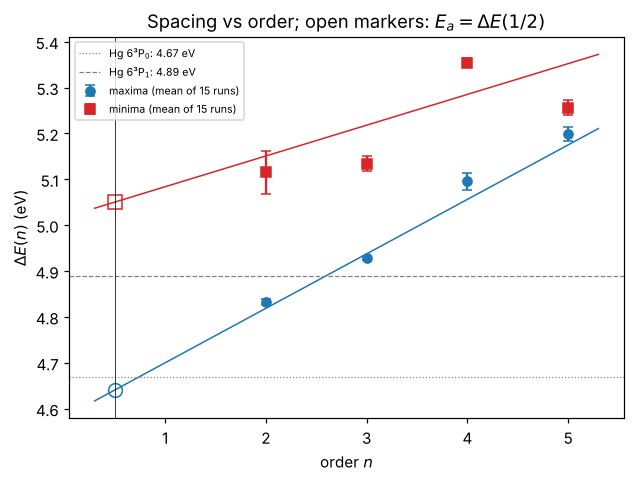

,E_a (eV),σ E_a (eV),σ E_a scaled (eV),λ/L,σ λ/L (scaled),χ²/ndf
maxima,4.641,0.013,0.036,0.013,0.002,7.922
minima,5.050,0.036,0.270,0.007,0.008,55.214


In [8]:
fits = {name: fh.fit_spacings(d) for name, d in dU.items()}

fig, ax = plt.subplots(figsize=(6.5, 4.5))
nn = np.linspace(0.3, 5.3, 200)
for (name, f), c, mk in zip(fits.items(), ["C0", "C3"], ["o", "s"]):
    ax.errorbar(f["n"], f["y"], yerr=f["sy"], fmt=mk, color=c, capsize=3, label=f"{name} (mean of {N} runs)")
    ax.plot(nn, fh.rapior(nn, *f["p"]), color=c, lw=1)
    ax.plot(0.5, f["Ea"], marker=mk, mfc="none", color=c, ms=9)
for (line, (E, _)), ls in zip(fh.HG_LINES.items(), [":", "--"]):
    ax.axhline(E, color="grey", ls=ls, lw=0.8, label=f"Hg {line.replace('₀', '$_0$').replace('₁', '$_1$')}: {E} eV")
ax.axvline(0.5, color="k", lw=0.5)
ax.set(xlabel="order $n$", ylabel=r"$\Delta E(n)$ (eV)",
       title=r"Spacing vs order; open markers: $E_a = \Delta E(1/2)$")
ax.legend(fontsize=7)
fig.savefig(FIG / "spacing_fit.png")
plt.show()

fit_tab = pd.DataFrame({name: {"E_a (eV)": f["Ea"], "σ E_a (eV)": f["sEa"], "σ E_a scaled (eV)": f["sEa_scaled"],
                               "λ/L": f["r"], "σ λ/L (scaled)": f["sr"], "χ²/ndf": f["chi2r"]}
                        for name, f in fits.items()}).T
display(fit_tab.round(4))

### Correlated spacings

Adjacent spacings share an extremum ($\Delta U_{12} = U_2 - U_1$ and
$\Delta U_{23} = U_3 - U_2$ both contain $U_2$), so their run-to-run fluctuations are
correlated. The fit above treats the four points as independent. Repeating it with the
full covariance matrix of the mean spacings, and the generalised
$\chi^2 = r^\mathsf{T} V^{-1} r$, shows how much this matters.

In [9]:
labels = [f"{k}→{k+1}" for k in range(1, 5)]
for name, d in dU.items():
    print(f"{name}: correlation matrix of the spacings over {N} runs")
    display(pd.DataFrame(np.corrcoef(d, rowvar=False), index=labels, columns=labels).round(2))

fits_cov = {name: fh.fit_spacings(d, full_cov=True) for name, d in dU.items()}
display(pd.DataFrame({name: {"E_a independent (eV)": fits[name]["Ea"], "χ²/ndf independent": fits[name]["chi2r"],
                             "E_a full cov. (eV)": f["Ea"], "σ E_a full cov. scaled (eV)": f["sEa_scaled"],
                             "χ²/ndf full cov.": f["chi2r"]}
                      for name, f in fits_cov.items()}).T.round(4))

maxima: correlation matrix of the spacings over 15 runs


,1→2,2→3,3→4,4→5
1→2,1.00,0.12,0.26,-0.24
2→3,0.12,1.00,0.27,-0.23
3→4,0.26,0.27,1.00,-0.86
4→5,-0.24,-0.23,-0.86,1.00


minima: correlation matrix of the spacings over 15 runs


,1→2,2→3,3→4,4→5
1→2,1.00,0.04,0.37,-0.06
2→3,0.04,1.00,-0.58,0.40
3→4,0.37,-0.58,1.00,-0.23
4→5,-0.06,0.40,-0.23,1.00


,E_a independent (eV),χ²/ndf independent,E_a full cov. (eV),σ E_a full cov. scaled (eV),χ²/ndf full cov.
maxima,4.641,7.922,4.611,0.034,13.880
minima,5.050,55.214,5.097,0.173,35.771


## 6. Systematic checks

**Smoothing window.** The extremum positions depend on how strongly the curve is
smoothed. Repeating the whole extraction and fit for several windows, half the spread
of $E_a$ is taken as a systematic uncertainty and added in quadrature to the (scaled)
statistical one.

**Run 5.** One run sits visibly apart from the others in the overlay. Its extremum
positions are compared with the spread of the other runs, and the fit is repeated
without it.

In [10]:
def summary(d):
    f = fh.fit_spacings(d)
    return {"E_a (eV)": f["Ea"], "σ E_a scaled (eV)": f["sEa_scaled"], "χ²/ndf": f["chi2r"],
            "pulls (σ)": np.round(f["pulls"], 1)}

windows = [0.3, 0.5, 0.8, 1.2]   # V; 0.5 V is used everywhere else
scan = []
for w in windows:
    for name, which in [("maxima", 0), ("minima", 1)]:
        U, kept = fh.extremum_positions(runs, which, smooth_V=w)
        scan.append({"extrema": name, "window (V)": w, "runs used": len(kept), **summary(np.diff(U, axis=1))})
scan = pd.DataFrame(scan).set_index(["extrema", "window (V)"]).sort_index()
display(scan)

budget = {}
for name, f in fits.items():
    Ea_w = scan.loc[name, "E_a (eV)"]
    s_syst = (Ea_w.max() - Ea_w.min()) / 2
    budget[name] = {"E_a (eV)": f["Ea"], "σ stat (eV)": f["sEa_scaled"],
                    "σ syst, window (eV)": s_syst, "σ total (eV)": np.hypot(f["sEa_scaled"], s_syst)}
budget = pd.DataFrame(budget).T
display(budget.round(4))

runs used  E_a (eV)  σ E_a scaled (eV)  χ²/ndf  \
extrema window (V)                                                   
maxima  0.3                15     4.618              0.033   1.619   
        0.5                15     4.641              0.036   7.922   
        0.8                15     4.646              0.021   3.509   
        1.2                15     4.677              0.012   1.884   
minima  0.3                14     4.928              0.064   0.427   
        0.5                15     5.050              0.269  55.213   
        0.8                14     5.061              0.165  36.927   
        1.2                15     5.065              0.046   4.845   

                                  pulls (σ)  
extrema window (V)                           
maxima  0.3         [-0.8, -0.2, 1.5, -0.5]  
        0.5           [2.1, -2.2, 2.1, 1.5]  
        0.8           [1.0, -1.4, 2.0, 0.0]  
        1.2         [-0.2, -0.1, 1.6, -1.1]  
minima  0.3          [0.0, -0.3, 0.8, -0.4]  
        0.5         [-0.8, -5.2, 6.9, -5.9]  
        0.8         [-0.2, -4.0, 6.6, -3.8]  
        1.2          [-1.6, 1.8, -1.9, 0.7]

,E_a (eV),σ stat (eV),"σ syst, window (eV)",σ total (eV)
maxima,4.641,0.036,0.029,0.046
minima,5.050,0.270,0.068,0.278


In [11]:
keep = np.arange(N) != 4    # run 5
display(pd.DataFrame([{"extrema": name, "runs": label, **summary(d[sel])}
                      for name, d in dU.items()
                      for label, sel in [("all 15", slice(None)), ("without run 5", keep)]]
                     ).set_index(["extrema", "runs"]).round(3))

for name, U in [("maxima", U_max), ("minima", U_min)]:
    dev = (U[4] - U[keep].mean(axis=0)) / U[keep].std(axis=0, ddof=1)
    print(f"run 5, {name}: offset of each extremum from the other runs' mean, in their std:", np.round(dev, 1))

E_a (eV)  σ E_a scaled (eV)  χ²/ndf  \
extrema runs                                                 
maxima  all 15            4.641              0.036   7.922   
        without run 5     4.626              0.050  23.401   
minima  all 15            5.050              0.269  55.213   
        without run 5     5.037              0.254  51.211   

                                     pulls (σ)  
extrema runs                                    
maxima  all 15           [2.1, -2.2, 2.1, 1.5]  
        without run 5   [2.4, -3.5, 5.1, -1.5]  
minima  all 15         [-0.8, -5.2, 6.9, -5.9]  
        without run 5  [-0.3, -5.0, 6.5, -5.9]

run 5, maxima: offset of each extremum from the other runs' mean, in their std: [ -6.   -9.7 -11.  -14.8  -6.7]
run 5, minima: offset of each extremum from the other runs' mean, in their std: [-0.1 -4.8 -9.5 -8.8 -4.2]


## 7. Comparison with the mercury levels

The measured $E_a$ is compared with the two levels that can be excited from the ground
state. Computing Planck's constant as $h = E_a \lambda / c$ is tempting, but $\lambda$
has to be *assigned* from the measured energy, so the result is just $E_a/E_\text{line}$
times the literature value. It is a consistency check of $E_a$, not an independent
measurement of $h$.

In [12]:
from scipy.constants import e, c, h as h_lit

rows = []
for name in fits:
    Ea, s = budget.loc[name, "E_a (eV)"], budget.loc[name, "σ total (eV)"]
    for line, (E, lam_nm) in fh.HG_LINES.items():
        h = Ea * e * lam_nm * 1e-9 / c
        rows.append({"extrema": name, "line": line, "E_a (eV)": Ea, "σ total (eV)": s,
                     "|E_a − E_line| / σ": abs(Ea - E) / s,
                     "h (10⁻³⁴ J s)": h / 1e-34, "deviation from h (%)": 100 * (h - h_lit) / h_lit})
display(pd.DataFrame(rows).set_index(["extrema", "line"]).round(3))

E_a (eV)  σ total (eV)  |E_a − E_line| / σ  h (10⁻³⁴ J s)  \
extrema line                                                              
maxima  6³P₀     4.641         0.046               0.637          6.587   
        6³P₁     4.641         0.046               5.426          6.292   
minima  6³P₀     5.050         0.278               1.368          7.169   
        6³P₁     5.050         0.278               0.577          6.847   

              deviation from h (%)  
extrema line                        
maxima  6³P₀                -0.586  
        6³P₁                -5.040  
minima  6³P₀                 8.188  
        6³P₁                 3.340

## 8. Summary

* **Maxima:** see the table below. $E_a$ agrees with the 6³P₀ level (4.67 eV) within its
  uncertainty and is clearly incompatible with 6³P₁.
* **Minima:** the fit is poor ($\chi^2/\mathrm{ndf} \gg 1$) and $E_a$ shifts
  strongly with the smoothing window. The minima are shallower and broader than the
  maxima, so their positions are more sensitive to the smoothing; the maxima give the
  more reliable result.
* **Run 5** is offset from the others by several standard deviations, but removing it
  barely changes $E_a$.

In [13]:
final = budget.assign(**{"closest level": [min(fh.HG_LINES, key=lambda k: abs(fh.HG_LINES[k][0] - E))
                                           for E in budget["E_a (eV)"]]})
final["level (eV)"] = [fh.HG_LINES[k][0] for k in final["closest level"]]
final["deviation (σ)"] = (final["E_a (eV)"] - final["level (eV)"]) / final["σ total (eV)"]
display(final.round(3))

,E_a (eV),σ stat (eV),"σ syst, window (eV)",σ total (eV),closest level,level (eV),deviation (σ)
maxima,4.641,0.036,0.029,0.046,6³P₀,4.67,-0.637
minima,5.050,0.269,0.068,0.278,6³P₁,4.89,0.577
